# Exploratory Data Analysis
This notebook looks at the **BAF Base** dataset (1,000,000 bank-account applications over months 0-7, about 1.1% fraud) before any model is built, and at how the five variants differ from it. Its job is to find what the modelling has to handle: hidden missing values, columns that drift over time, rare fraud, the link between age and fraud, and how the variants differ.

Anything that compares a feature with fraud uses **training months 0-3 only** (section 2.2), so the later choices are not shaped by the months used to test the model.

Outline:
1. Imports
2. Read data: column groups, training months only
3. Data analysis: quality, the target, numeric and categorical columns, correlation, predictive power of single features, drift over time, Benford's law, age and fairness, the variants
4. Summary: each finding with the action it leads to and where that action is carried out (mostly notebook 02)

## **1. Import Statements**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# Plot settings, so every chart looks the same
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

## **2. Read Data**

In [2]:
base = pd.read_csv('../data/Base.csv')
# income is stored with floating-point noise (e.g. 0.6000000000000001), so round it
base['income'] = base['income'].round(1)

### **2.1 Column Groups**
The target is `fraud_bool`. The other columns are grouped by type so later sections can loop over them.

In [3]:
TARGET = 'fraud_bool'

categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']

binary_cols = ['email_is_free', 'phone_home_valid', 'phone_mobile_valid',
               'has_other_cards', 'foreign_request', 'keep_alive_session']

# Everything else is numeric (apart from the target and month)
numeric_cols = []
for col in base.columns:
    if col not in categorical_cols + binary_cols + [TARGET, 'month']:
        numeric_cols.append(col)

print(len(numeric_cols), 'numeric:', numeric_cols)
print(len(categorical_cols), 'categorical:', categorical_cols)
print(len(binary_cols), 'binary:', binary_cols)

19 numeric: ['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'credit_risk_score', 'bank_months_count', 'proposed_credit_limit', 'session_length_in_minutes', 'device_distinct_emails_8w', 'device_fraud_count']
5 categorical: ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
6 binary: ['email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'has_other_cards', 'foreign_request', 'keep_alive_session']


### **2.2 Training Months Only**
Anything that compares a feature with fraud (and so could shape our modelling choices) uses **months 0-3 only**.

In [4]:
train = base[base['month'] <= 3]
print(f'Training months 0-3: {len(train):,} rows, {train[TARGET].sum():,} fraud cases')

Training months 0-3: 547,975 rows, 5,288 fraud cases


## **3. Data Analysis**

### **3.1 Data Quality**

The dataset's datasheet says missing values are stored as `-1` (and as any negative number for `intended_balcon_amount`). So we count those instead, and check whether being missing is itself linked to fraud.

In [5]:
missing_cols = ['prev_address_months_count', 'current_address_months_count',
                'bank_months_count', 'session_length_in_minutes',
                'device_distinct_emails_8w', 'intended_balcon_amount']

def is_missing(df, col):
    """True where the value is missing. intended_balcon_amount uses any negative number, the rest use -1."""
    if col == 'intended_balcon_amount':
        return df[col] < 0
    return df[col] == -1

rows = []
for col in missing_cols:
    missing_in_train = is_missing(train, col)
    rows.append({
        'column': col,
        '% missing': is_missing(base, col).mean() * 100,
        'fraud rate when missing (%)': train.loc[missing_in_train, TARGET].mean() * 100,
        'fraud rate when present (%)': train.loc[~missing_in_train, TARGET].mean() * 100,
    })

missing_table = pd.DataFrame(rows).round(2)
missing_table

,column,% missing,fraud rate when missing (%),fraud rate when present (%)
0,prev_address_months_count,71.29,1.28,0.27
1,current_address_months_count,0.43,0.30,0.97
2,bank_months_count,25.36,1.40,0.82
3,session_length_in_minutes,0.20,0.90,0.97
4,device_distinct_emails_8w,0.04,1.33,0.96
5,intended_balcon_amount,74.25,1.15,0.49


Finding duplicates and constant columns:

In [6]:
print('Duplicate rows:', base.duplicated().sum())

constant_cols = []
for col in base.columns:
    if base[col].nunique() == 1:
        constant_cols.append(col)
print('Columns with only one value:', constant_cols)

numeric_cols = [col for col in numeric_cols if col not in constant_cols]

Duplicate rows: 0


Columns with only one value: ['device_fraud_count']


**Findings**
- No duplicate rows. `device_fraud_count` is always 0, so it can be dropped.
- Missing values are hidden as `-1` / negatives: `intended_balcon_amount` (74%), `prev_address_months_count` (71%) and `bank_months_count` (25%) are mostly or often missing. The other three are under 0.5%.
- **Being missing is linked to fraud.** When `prev_address_months_count` is missing the fraud rate is 1.28%, vs 0.27% when present (about 5x). `intended_balcon_amount` (1.15% vs 0.49%) and `bank_months_count` (1.40% vs 0.82%) show the same pattern. So in preprocessing we should add a "was missing" flag for each column, not just fill the gap.
- `credit_risk_score` and `velocity_6h` have some negative values, but the datasheet lists these as normal values, not missing.

### **3.2 Analysis on Target**

In [7]:
# 1. Overall fraud rate
overall_rate = base[TARGET].mean()
print(f'Overall fraud rate: {overall_rate:.2%} ({base[TARGET].sum():,} fraud cases out of {len(base):,})')

Overall fraud rate: 1.10% (11,029 fraud cases out of 1,000,000)


,applications,fraud cases,fraud rate (%)
month,,,
0,132440,1500,1.13
1,127620,1198,0.94
2,136979,1198,0.87
3,150936,1392,0.92
4,127691,1452,1.14
5,119323,1411,1.18
6,108168,1450,1.34
7,96843,1428,1.47


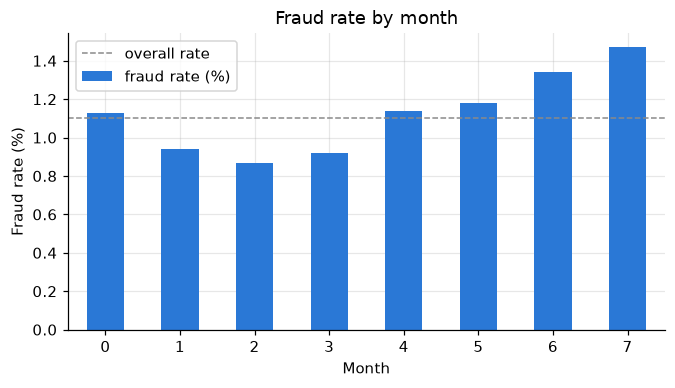

In [8]:
# 2. Fraud rate per month
by_month = base.groupby('month')[TARGET].agg(['count', 'sum', 'mean'])
by_month.columns = ['applications', 'fraud cases', 'fraud rate (%)']
by_month['fraud rate (%)'] = (by_month['fraud rate (%)'] * 100).round(2)
display(by_month)

ax = by_month['fraud rate (%)'].plot(kind='bar', color=BLUE, figsize=(7, 3.5), rot=0)
ax.axhline(overall_rate * 100, color=GREY, linestyle='--', linewidth=1, label='overall rate')
ax.set_title('Fraud rate by month')
ax.set_xlabel('Month')
ax.set_ylabel('Fraud rate (%)')
ax.legend()
plt.show()

**Findings**
- Only **1.10%** of applications are fraud (11,029 out of 1,000,000). Accuracy is useless here: predicting "not fraud" for everyone scores 98.9%. We need metrics that focus on the fraud class (e.g. recall at a fixed false positive rate, PR-AUC).
- The fraud rate is **not stable over time**. It is around 0.9% in months 1-3 and rises to 1.34% and 1.47% in months 6-7, while the number of applications falls (151k in month 3, 97k in month 7). So the test months have more fraud than the training months, which matters for choosing thresholds and for calibration.

### **3.3 Analysis on Numeric Columns**

In [9]:
# Skew: 0 means symmetric, a large positive number means a long right tail
skew_table = base[numeric_cols].skew().sort_values(ascending=False).round(2)
skew_table.to_frame('skew')

,skew
days_since_request,9.28
prev_address_months_count,4.06
session_length_in_minutes,3.30
bank_branch_count_8w,2.75
intended_balcon_amount,2.51
device_distinct_emails_8w,2.43
zip_count_4w,1.46
current_address_months_count,1.39
proposed_credit_limit,1.30
date_of_birth_distinct_emails_4w,0.70


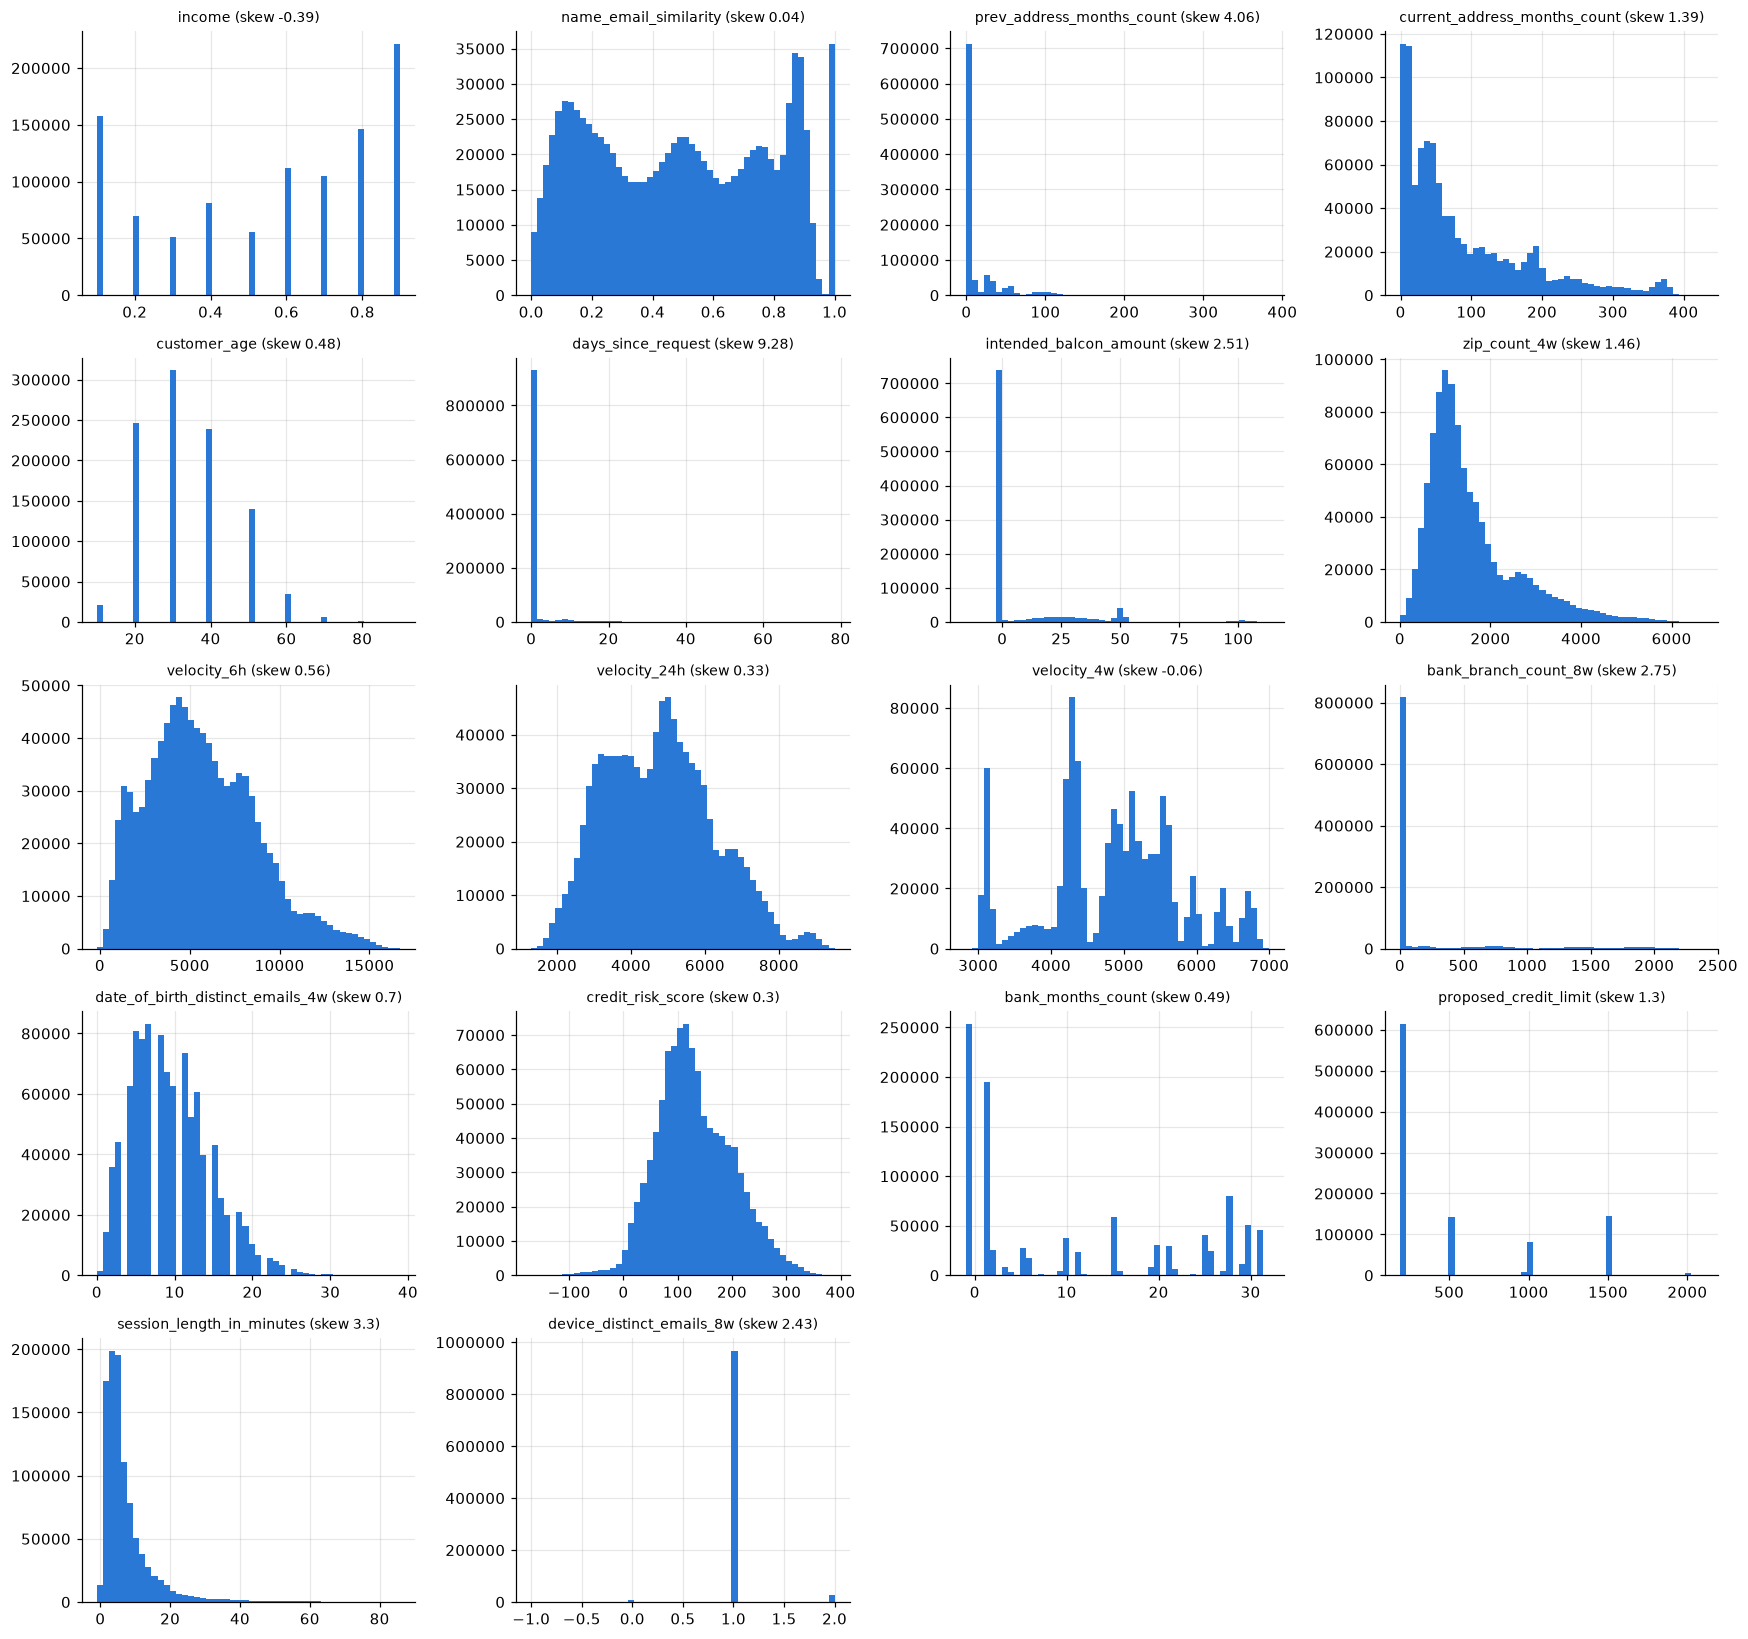

In [10]:
# One histogram per numeric column
n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    ax.hist(base[col], bins=50, color=BLUE)
    ax.set_title(f'{col} (skew {skew_table[col]})', fontsize=9)
    ax.ticklabel_format(axis='y', style='plain')  # show 1000000, not 1e6

# Hide the empty panels at the end
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

**Findings**
- Several columns have long right tails: `days_since_request` (skew 9.3), `prev_address_months_count` (4.1), `session_length_in_minutes` (3.3), `bank_branch_count_8w` (2.8). A log transform would help a linear model (however, tree models like LightGBM don't need it).
- Some "numeric" columns only take a few values: `income` (9 deciles), `customer_age` (9 decades), `proposed_credit_limit` (12 values), `device_distinct_emails_8w` (4 values).
- The tall spikes at -1 / 0 in some charts are the hidden missing values from 3.1.

### **3.4 Analysis on Categorical Columns**

Every column has at most 7 categories, so all of them are shown.

**How to read each pair of charts:**
- **Left: how common each category is.** The % of all applications that fall in each category (the bars add up to 100%). This is about the data, not about fraud.
- **Right: how risky each category is.** Out of the applications in that category, the % that were fraud (months 0-3 only).
- **Dashed line: the overall fraud rate** across all applications in months 0-3 (0.97%). A bar above the line means that category has more fraud than average, and a bar below means less.

The two charts answer different questions. A category can be rare on the left but very risky on the right (or the other way round), so read them together. Note that the fraud rate of a very small category is based on few applications, so it can jump around.

The binary (0/1) columns use the same pair of charts, with the two values 0 and 1 as the categories.

In [11]:
def plot_category(col):
    """Left: how common each category is. Right: % of each category that is fraud (months 0-3)."""
    share = base[col].value_counts(normalize=True) * 100
    fraud_rate = train.groupby(col)[TARGET].mean() * 100
    fraud_rate = fraud_rate.reindex(share.index)  # same order as the left chart

    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3))

    share.plot(kind='bar', ax=left, color=BLUE, rot=0)
    left.set_title(f'{col}: share of applications')
    left.set_ylabel('% of applications')
    left.set_xlabel('')

    fraud_rate.plot(kind='bar', ax=right, color=BLUE, rot=0, label='fraud rate in this category')
    right.axhline(train[TARGET].mean() * 100, color=GREY, linestyle='--', linewidth=1,
                  label='overall fraud rate')
    right.set_title(f'{col}: % of each category that is fraud')
    right.set_ylabel('Fraud rate (%)')
    right.set_xlabel('')
    right.legend()

    plt.tight_layout()
    plt.show()

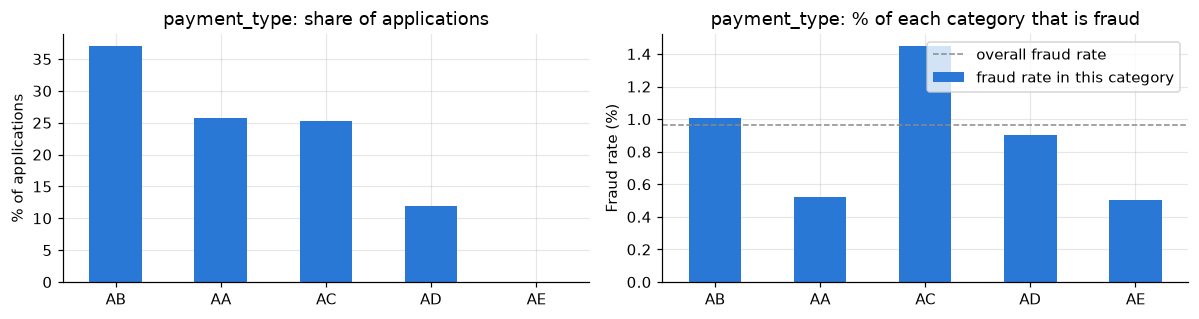

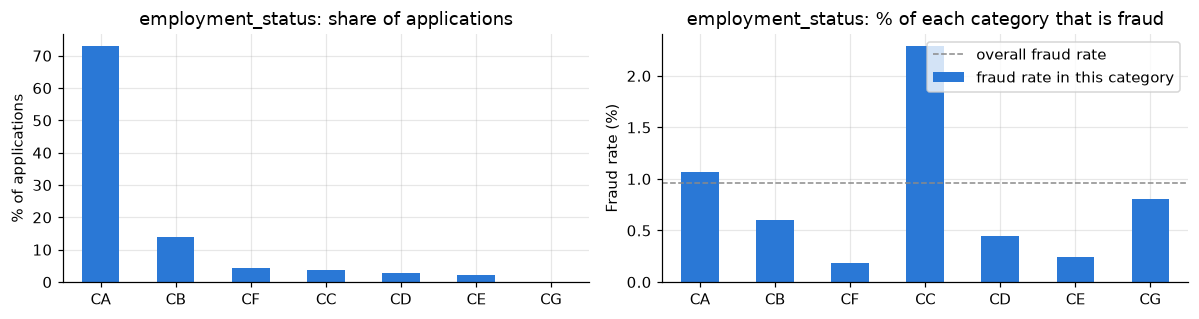

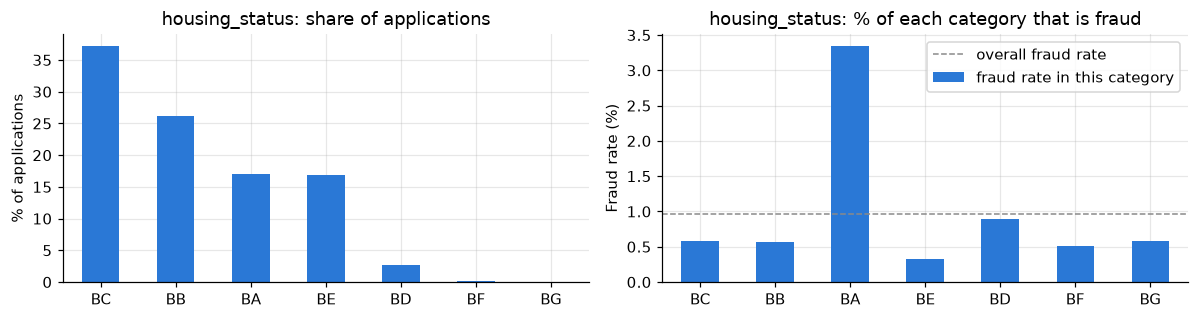

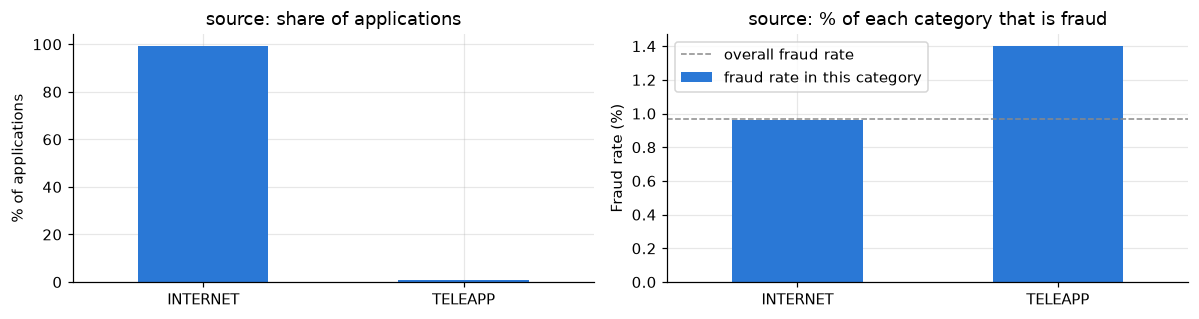

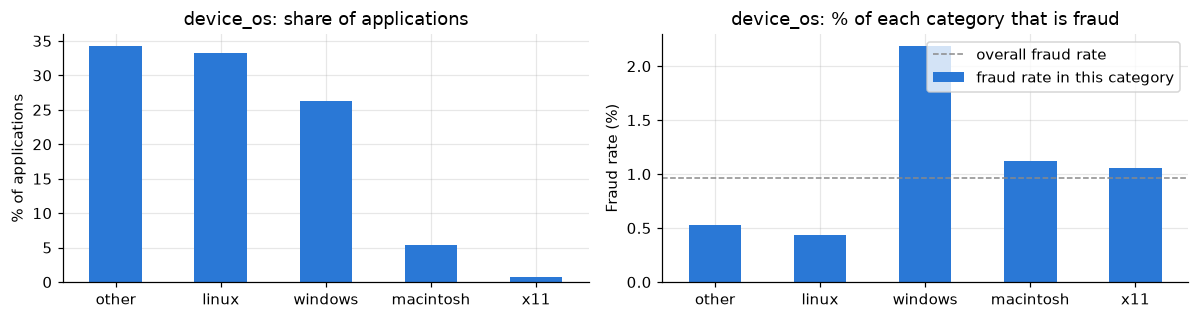

In [12]:
for col in categorical_cols:
    plot_category(col)

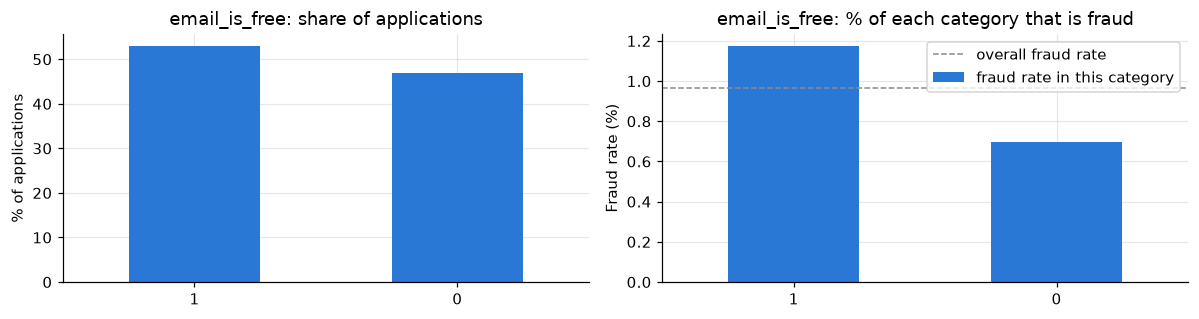

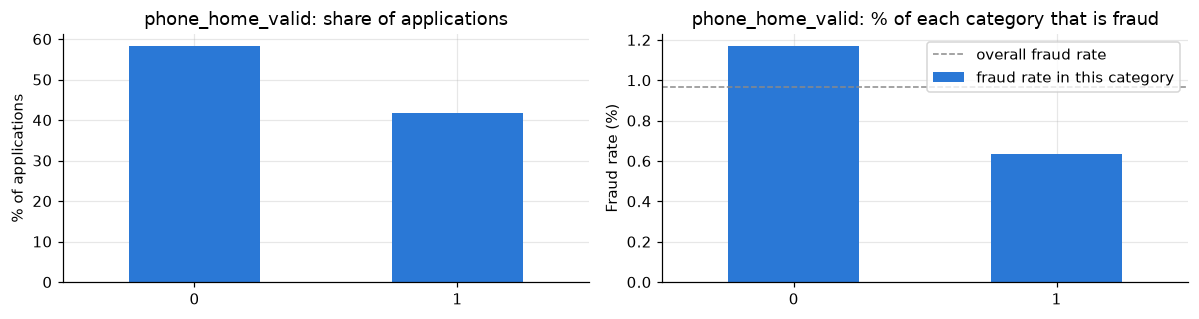

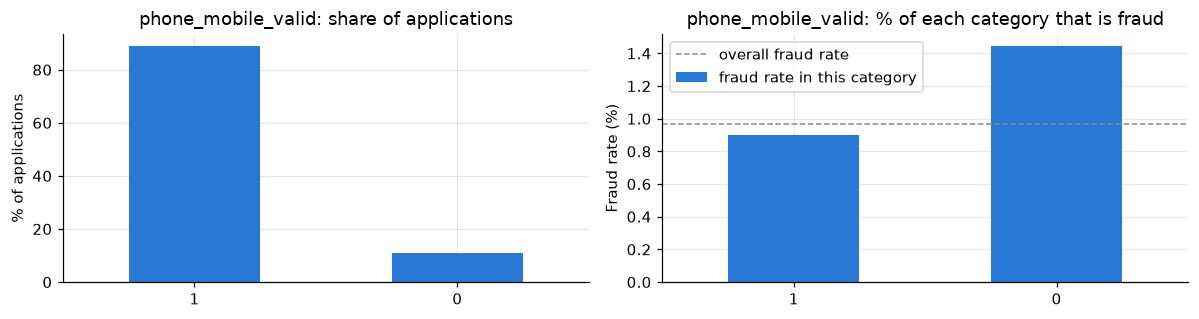

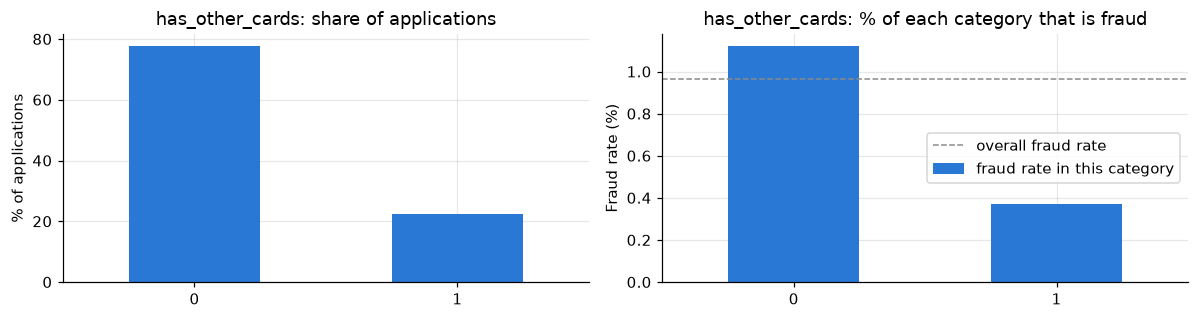

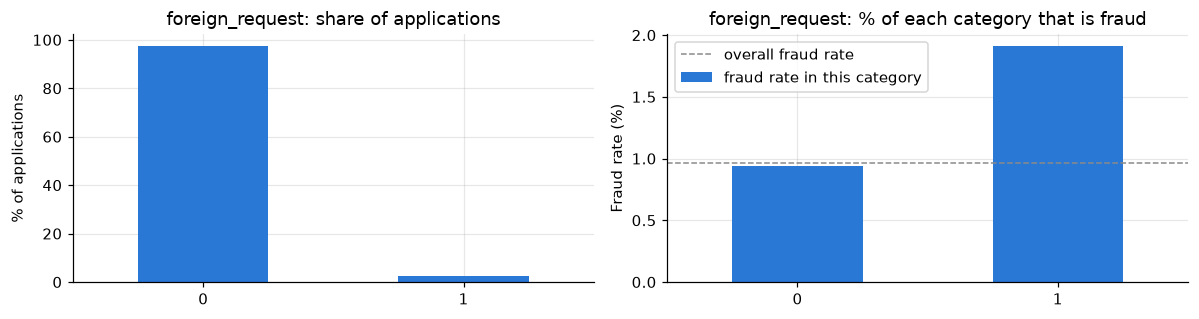

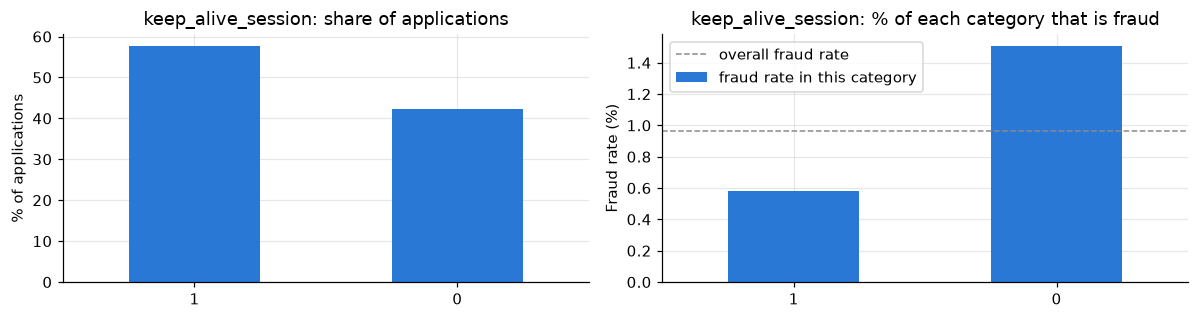

In [13]:
# The binary (0/1) columns work the same way
for col in binary_cols:
    plot_category(col)

**Findings**
- Some categories stand out strongly (fraud rates from months 0-3, average 0.97%):
  - `housing_status` **BA**: 3.35%, about 6x most other categories (0.3-0.6%).
  - `device_os` **windows**: 2.19%, vs 0.44% for linux.
  - `employment_status` **CC**: 2.29%. `payment_type` **AC**: 1.45%.
- Binary flags: `keep_alive_session = 0` (1.51% vs 0.58%), `has_other_cards = 0` (1.12% vs 0.37%), `foreign_request = 1` (1.91% vs 0.94%), `phone_home_valid = 0` (1.17% vs 0.64%).
- Rare categories (under 1% of rows): `payment_type` AE, `employment_status` CG, `housing_status` BF and BG, `source` TELEAPP, `device_os` x11. For one-hot encoding the tiny ones (AE, CG, BF, BG) can be merged into an "other" group.

### **3.5 Correlation**

Spearman (rank) correlation is used because many columns are skewed. For correlation with the target there is only one column of numbers, which reads better as a sorted bar chart than as a heatmap.

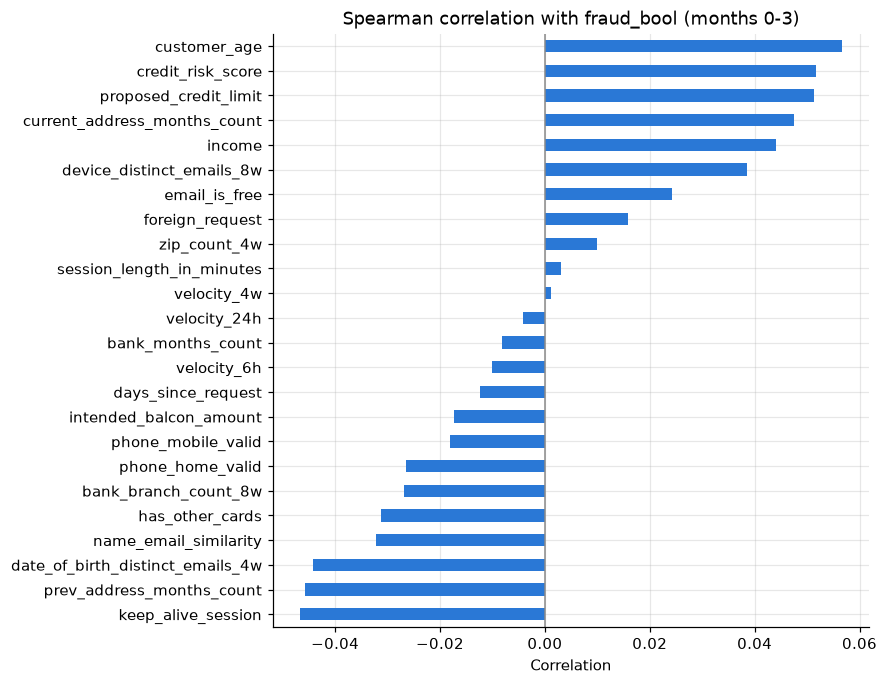

In [14]:
# Correlation of each numeric/binary feature with fraud (months 0-3)
corr_with_target = train[numeric_cols + binary_cols].corrwith(train[TARGET], method='spearman')
corr_with_target = corr_with_target.sort_values()

ax = corr_with_target.plot(kind='barh', color=BLUE, figsize=(7, 7))
ax.axvline(0, color=GREY, linewidth=1)
ax.set_title('Spearman correlation with fraud_bool (months 0-3)')
ax.set_xlabel('Correlation')
plt.show()

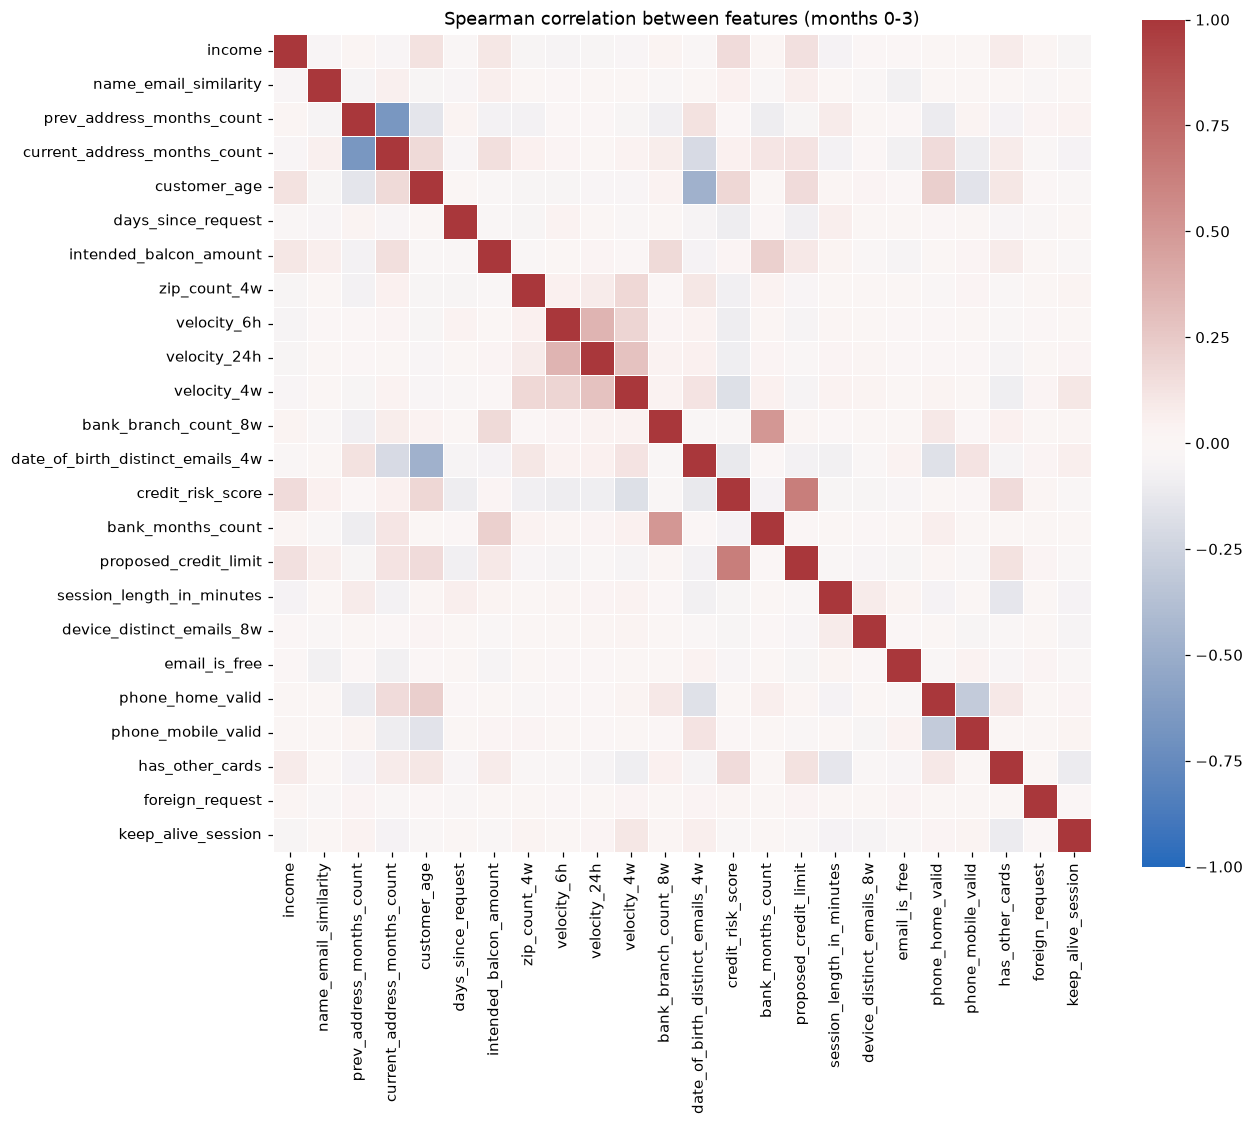

In [15]:
# Correlation between features
corr = train[numeric_cols + binary_cols].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Spearman correlation between features (months 0-3)')
plt.show()

In [16]:
# List the strongly correlated pairs, so we don't have to read them off the heatmap
cols = corr.columns
pairs = []
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.4:
            pairs.append({'feature 1': cols[i], 'feature 2': cols[j], 'spearman': round(r, 2)})

pd.DataFrame(pairs).sort_values('spearman', key=abs, ascending=False)

,feature 1,feature 2,spearman
0,prev_address_months_count,current_address_months_count,-0.66
3,credit_risk_score,proposed_credit_limit,0.64
2,bank_branch_count_8w,bank_months_count,0.50
1,customer_age,date_of_birth_distinct_emails_4w,-0.47


**Findings**
- All correlations with the target are small (largest is about 0.06 for `customer_age`). That is expected when only 1% of rows are fraud: correlation is not a good measure of strength here, so 3.6 uses AUC instead. The **direction** is still useful, e.g. older age, higher income and higher credit limit go with more fraud, and `keep_alive_session` / `has_other_cards` go with less.
- No two features are near-duplicates (the strongest pair is -0.66). The notable pairs are `prev_address_months_count` / `current_address_months_count` (-0.66), `credit_risk_score` / `proposed_credit_limit` (0.64), `bank_branch_count_8w` / `bank_months_count` (0.50) and `customer_age` / `date_of_birth_distinct_emails_4w` (-0.47).

### **3.6 Feature Predictivity Power**

**Single-feature AUC:** if we ranked applications using only this one column, how well would it separate fraud from non-fraud? 0.5 is no better than random and 1.0 is perfect.

How the table works:
- **`auc`**: how strong the feature is on its own. Some features work "in reverse" (lower values mean more fraud), which gives an AUC below 0.5. A feature with AUC 0.3 is just as useful as one with 0.7, only flipped, so we always report the stronger side (0.7).
- **`relationship`**: which way round the feature works.
  - *higher value → more likely fraud*: e.g. older `customer_age` goes with more fraud.
  - *higher value → less likely fraud*: e.g. `keep_alive_session = 1` goes with less fraud. For binary columns, "higher value" just means 1 instead of 0.
  - *categories (see 3.4)*: categories like `housing_status` have no order, so there is no "higher". To score them, each category is replaced by its fraud rate, and the charts in 3.4 show which categories are the risky ones.

In [17]:
def single_feature_auc(df, target, cols, target_name):
    """AUC of each column on its own for predicting `target` (a 0/1 Series).
    target_name is only used for the wording, e.g. 'fraud'."""
    rows = []
    for col in cols:
        if col in categorical_cols:
            # replace each category with its average target value, so it can be used as a score
            score = df[col].map(target.groupby(df[col]).mean())
        else:
            score = df[col]

        auc = roc_auc_score(target, score)

        if col in categorical_cols:
            relationship = 'categories (see 3.4)'
        elif auc >= 0.5:
            relationship = f'higher value → more likely {target_name}'
        else:
            relationship = f'higher value → less likely {target_name}'

        rows.append({
            'feature': col,
            'auc': round(max(auc, 1 - auc), 3),  # an AUC of 0.3 is as useful as 0.7, just reversed
            'relationship': relationship,
        })
    return pd.DataFrame(rows).sort_values('auc', ascending=False).reset_index(drop=True)


all_features = numeric_cols + binary_cols + categorical_cols
auc_table = single_feature_auc(train, train[TARGET], all_features, target_name='fraud')
auc_table

,feature,auc,relationship
0,housing_status,0.710,categories (see 3.4)
1,device_os,0.687,categories (see 3.4)
2,customer_age,0.662,higher value → more likely fraud
3,credit_risk_score,0.653,higher value → more likely fraud
4,current_address_months_count,0.640,higher value → more likely fraud
5,proposed_credit_limit,0.632,higher value → more likely fraud
6,date_of_birth_distinct_emails_4w,0.630,higher value → less likely fraud
7,income,0.629,higher value → more likely fraud
8,keep_alive_session,0.618,higher value → less likely fraud
9,prev_address_months_count,0.611,higher value → less likely fraud


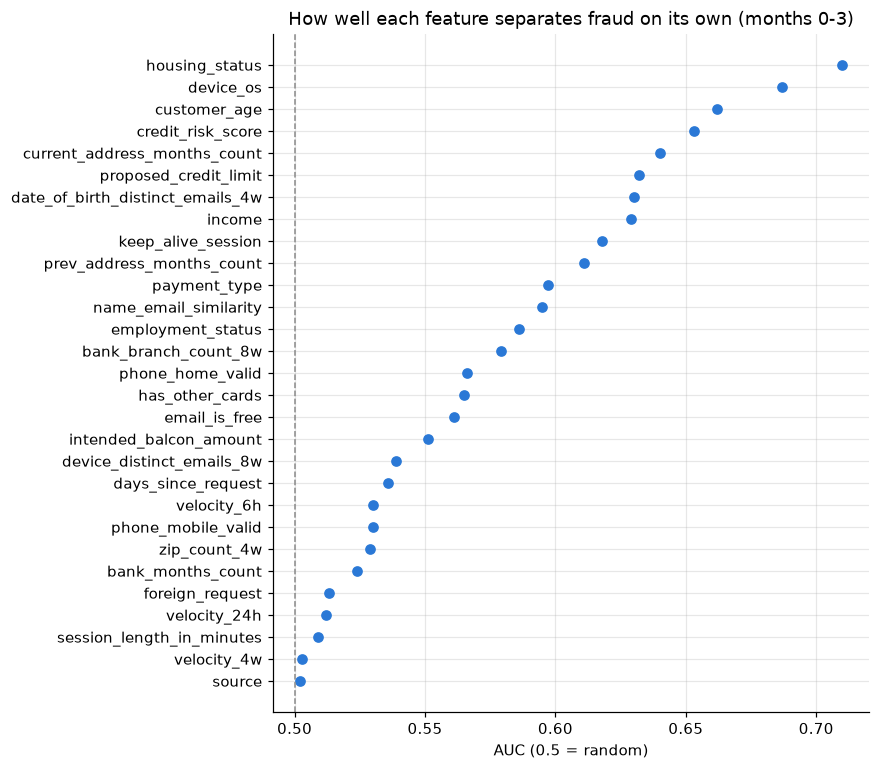

In [18]:
plot_data = auc_table.sort_values('auc')

plt.figure(figsize=(7, 8))
plt.scatter(plot_data['auc'], plot_data['feature'], color=BLUE)
plt.axvline(0.5, color=GREY, linestyle='--', linewidth=1)
plt.title('How well each feature separates fraud on its own (months 0-3)')
plt.xlabel('AUC (0.5 = random)')
plt.show()

**Findings**
- The most useful single features are `housing_status` (AUC 0.71), `device_os` (0.69), `customer_age` (0.66) and `credit_risk_score` (0.65). No single feature is strong, so the model has to combine many.
- The least useful are `source`, `velocity_4w`, `session_length_in_minutes` and `velocity_24h` (all close to 0.5).
- **No sign of leakage:** no feature scores above 0.8 on its own. `month` is not a feature and must never be given to the model.

### **3.7 Drift Over Time**

Now we score how much each feature moved between the training months (0-3) and the test months (6-7) with the **Population Stability Index (PSI)**, then only plot the features that moved most. This only looks at feature values, never at fraud labels.

Rule of thumb:
- PSI below 0.1 = stable,
- 0.1-0.25 = some shift,
- above 0.25 = large shift.

These are the two grey lines on the chart below: features left of the dotted line are stable, and features right of the dashed line have shifted a lot.

In [19]:
def psi(reference, current, bins=10):
    """Population Stability Index between two samples of the same column."""
    if pd.api.types.is_numeric_dtype(reference) and reference.nunique() > bins:
        # Put both samples into the same bins, using deciles of the reference sample
        edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
        edges[0] = -np.inf
        edges[-1] = np.inf
        reference = pd.cut(reference, edges)
        current = pd.cut(current, edges)

    ref_pct = reference.value_counts(normalize=True)
    cur_pct = current.value_counts(normalize=True).reindex(ref_pct.index, fill_value=0)

    # A tiny floor avoids log(0) when a bin is empty
    ref_pct = ref_pct.clip(lower=0.0001)
    cur_pct = cur_pct.clip(lower=0.0001)
    return ((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)).sum()


test_months = base[base['month'] >= 6]

rows = []
for col in all_features:
    rows.append({'feature': col, 'psi': psi(train[col], test_months[col])})

psi_table = pd.DataFrame(rows).sort_values('psi', ascending=False).round(3).reset_index(drop=True)
psi_table.head(10)

,feature,psi
0,velocity_4w,4.317
1,velocity_24h,2.096
2,velocity_6h,1.248
3,zip_count_4w,0.543
4,date_of_birth_distinct_emails_4w,0.458
5,credit_risk_score,0.323
6,proposed_credit_limit,0.103
7,income,0.102
8,session_length_in_minutes,0.081
9,name_email_similarity,0.056


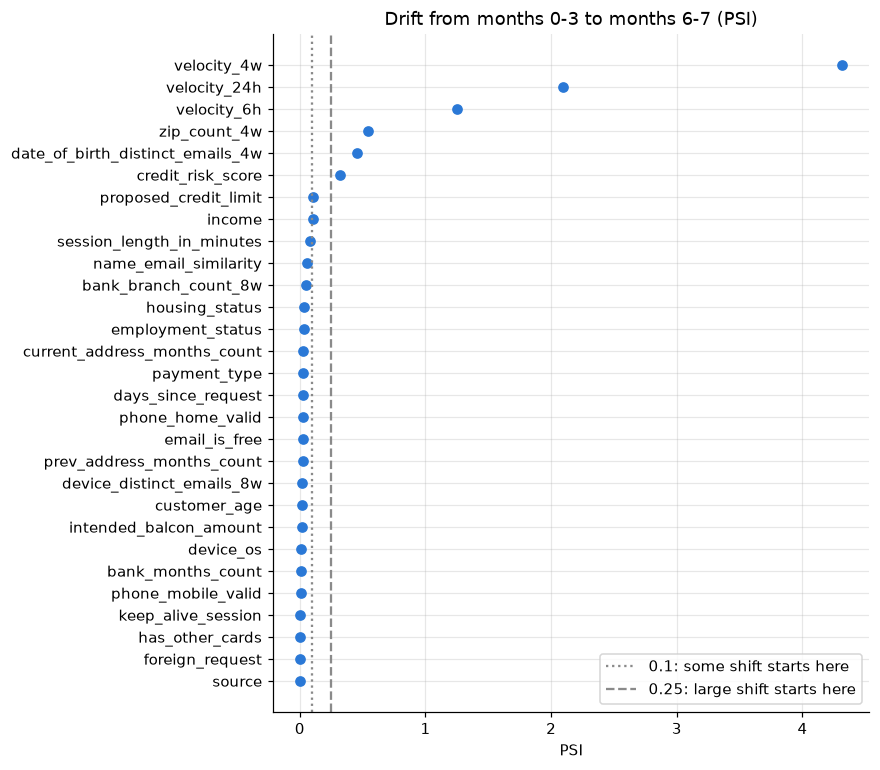

In [20]:
plot_data = psi_table.sort_values('psi')

plt.figure(figsize=(7, 8))
plt.scatter(plot_data['psi'], plot_data['feature'], color=BLUE)
plt.axvline(0.1, color=GREY, linestyle=':', linewidth=1.5, label='0.1: some shift starts here')
plt.axvline(0.25, color=GREY, linestyle='--', linewidth=1.5, label='0.25: large shift starts here')
plt.title('Drift from months 0-3 to months 6-7 (PSI)')
plt.xlabel('PSI')
plt.legend(loc='lower right')
plt.show()

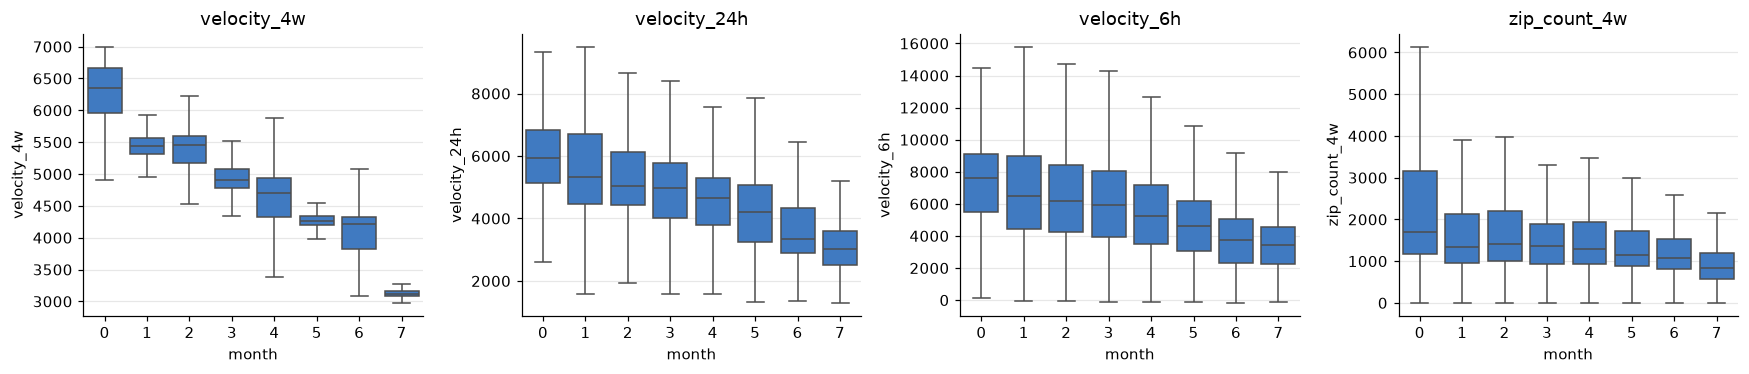

In [21]:
# Month-by-month view of the 4 numeric features that drifted most
top_drifters = psi_table[psi_table['feature'].isin(numeric_cols)]['feature'].head(4)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, top_drifters):
    sns.boxplot(data=base, x='month', y=col, ax=ax, color=BLUE, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Findings**
- Most features are stable (PSI under 0.1), but a few shift a lot: `velocity_4w` (PSI 4.3), `velocity_24h` (2.1), `velocity_6h` (1.2), `zip_count_4w` (0.54), `date_of_birth_distinct_emails_4w` (0.46) and `credit_risk_score` (0.32).
- The `velocity_*` and `*_4w` columns are counts over a recent time window, so they fall steadily as the number of applications falls (see the boxplots). By month 7, 85% of `velocity_4w` values are below the 1st percentile of the training months.
- In preprocessing / feature engineering, can possibly try (1) dropping these columns or (2) expressing them relative to their own month, and keep whichever does better on the validation month.

### **3.8 Benford's Law**
Benford's law says that in many naturally occurring sets of numbers (amounts, counts, durations), the first digit is **not** evenly spread. About 30% of numbers start with 1 and only about 5% start with 9. The expected share for each first digit $d$ is $\log_{10}(1 + 1/d)$.

**Which columns are eligible?** Benford's law only makes sense for numbers that:
1. are **positive**. We drop zeros and the `-1` missing values.
2. take **many different values** (at least 100). Codes, deciles and small counts like `income`, `customer_age` or `proposed_credit_limit` don't qualify.
3. **span several orders of magnitude**: the 99th percentile is at least 100x the 1st percentile.

In [22]:
rows = []
for col in numeric_cols:
    positive = train[col][train[col] > 0]   # Benford only applies to positive numbers
    rows.append({
        'feature': col,
        'distinct values': train[col].nunique(),
        '% positive': round(len(positive) / len(train) * 100, 1),
        'spread (p99 / p1)': round(positive.quantile(0.99) / positive.quantile(0.01), 1),
    })

eligibility = pd.DataFrame(rows)
eligibility['eligible'] = (eligibility['distinct values'] >= 100) & (eligibility['spread (p99 / p1)'] >= 100)
eligibility = eligibility.sort_values('spread (p99 / p1)', ascending=False).reset_index(drop=True)
display(eligibility)

benford_cols = eligibility.loc[eligibility['eligible'], 'feature'].tolist()
print('Benford-eligible columns:', benford_cols)

,feature,distinct values,% positive,spread (p99 / p1),eligible
0,days_since_request,544952,100.0,79128.3,True
1,bank_branch_count_8w,2298,85.7,1996.0,True
2,current_address_months_count,420,98.6,372.0,True
3,intended_balcon_amount,546513,28.2,61.8,False
4,session_length_in_minutes,545938,99.8,55.2,False
5,name_email_similarity,547609,100.0,52.8,False
6,prev_address_months_count,367,31.1,39.6,False
7,credit_risk_score,550,97.9,34.1,False
8,bank_months_count,33,75.0,31.0,False
9,date_of_birth_distinct_emails_4w,40,99.9,24.0,False


Benford-eligible columns: ['days_since_request', 'bank_branch_count_8w', 'current_address_months_count']


**How we measure the fit.** For each eligible column we count how often each first digit (1-9) appears and compare it with Benford's expected share. The gap is summarised with the **mean absolute deviation (MAD)**, the average of the 9 gaps. These thresholds are Nigrini's for first digits:

| MAD | Meaning |
|---|---|
| below 0.006 | close conformity |
| 0.006 - 0.012 | acceptable conformity |
| 0.012 - 0.015 | marginally acceptable |
| above 0.015 | does not conform |

We check genuine and fraud applications separately (months 0-3), to see whether fraud cases break the pattern more.

In [23]:
digits = np.arange(1, 10)
benford_expected = pd.Series(np.log10(1 + 1 / digits), index=digits)


def first_digit_shares(values):
    """Share of values whose first digit is 1, 2, ..., 9.
    Scientific notation always starts with the first digit: 0.0372 -> '3.720000e-02', 4510 -> '4.510000e+03'."""
    first_digits = values.map(lambda x: int(f'{x:e}'[0]))
    return first_digits.value_counts(normalize=True).reindex(digits, fill_value=0)


def conformity(mad):
    """Nigrini's first-digit thresholds."""
    if mad < 0.006:
        return 'close'
    elif mad < 0.012:
        return 'acceptable'
    elif mad < 0.015:
        return 'marginal'
    else:
        return 'does not conform'


shares = {}   # (column, group) -> share of each first digit
rows = []
for col in benford_cols:
    positive = train[train[col] > 0]
    groups = {
        'all': positive,
        'not fraud': positive[positive[TARGET] == 0],
        'fraud': positive[positive[TARGET] == 1],
    }
    for group_name, group in groups.items():
        observed = first_digit_shares(group[col])
        mad = (observed - benford_expected).abs().mean()
        shares[(col, group_name)] = observed
        rows.append({'feature': col, 'group': group_name, 'rows': len(group),
                     'MAD': round(mad, 4), 'conformity': conformity(mad)})

benford_table = pd.DataFrame(rows)
benford_table

,feature,group,rows,MAD,conformity
0,days_since_request,all,547975,0.0234,does not conform
1,days_since_request,not fraud,542687,0.0234,does not conform
2,days_since_request,fraud,5288,0.0261,does not conform
3,bank_branch_count_8w,all,469617,0.0457,does not conform
4,bank_branch_count_8w,not fraud,465516,0.0455,does not conform
5,bank_branch_count_8w,fraud,4101,0.0648,does not conform
6,current_address_months_count,all,540362,0.0083,acceptable
7,current_address_months_count,not fraud,535092,0.0083,acceptable
8,current_address_months_count,fraud,5270,0.0189,does not conform


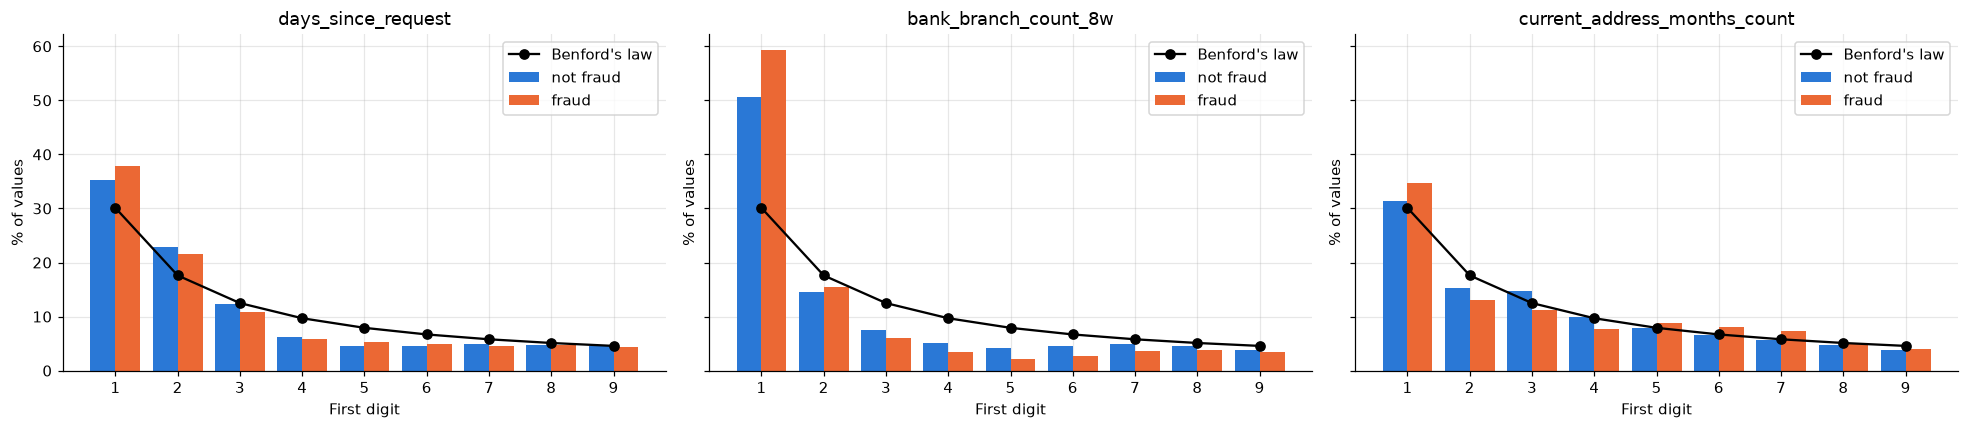

In [24]:
# Observed first digits vs Benford's expected share, genuine and fraud applications side by side
fig, axes = plt.subplots(1, len(benford_cols), figsize=(6 * len(benford_cols), 4), sharey=True)
bar_width = 0.4

for ax, col in zip(axes, benford_cols):
    not_fraud = shares[(col, 'not fraud')] * 100
    fraud = shares[(col, 'fraud')] * 100

    ax.bar(digits - bar_width / 2, not_fraud, width=bar_width, color=BLUE, label='not fraud')
    ax.bar(digits + bar_width / 2, fraud, width=bar_width, color=ORANGE, label='fraud')
    ax.plot(digits, benford_expected * 100, color='black', marker='o', linewidth=1.5, label="Benford's law")

    ax.set_title(col)
    ax.set_xticks(digits)
    ax.set_xlabel('First digit')
    ax.set_ylabel('% of values')
    ax.legend()

plt.tight_layout()
plt.show()

**Findings**
- Only **3 of the 18 numeric columns** are eligible: `days_since_request`, `bank_branch_count_8w` and `current_address_months_count`. The rest are codes, deciles or small counts, or sit in a narrow range.
- Only `current_address_months_count` follows Benford reasonably well (MAD 0.008, acceptable). The other two do not conform:
  - `bank_branch_count_8w` (MAD 0.046) has far too many 1s (51% vs 30% expected), because most of its values are small counts.
  - `days_since_request` (MAD 0.023) has too few 4s and 5s, and digits 5-9 are almost flat instead of falling away.
- **Fraud applications deviate more than genuine ones** in two columns: `current_address_months_count` (0.019 vs 0.008, which drops from acceptable to does not conform) and `bank_branch_count_8w` (0.065 vs 0.046). For `days_since_request` the two groups are about the same (0.026 vs 0.023).
- **Caveats:**
  - BAF was synthetically generated by a model trained on real bank data, so how well it follows Benford partly reflects that generator, not real human behaviour.
- **Action:** report this as supporting evidence that fraud applications look different, not as a model feature.

### **3.9 Age and Fairness**

#### Why this section matters
We treat `customer_age` as a **protected attribute**: a personal characteristic that a decision about someone should not be based on. Banks are expected to justify any use of attributes like age in automated decisions. The BAF dataset is designed around age as well: each variant takes the same two groups (aged 50+ and under 50) and deliberately makes them differ in one way, such as group size, fraud rate or how easy fraud is to detect (see 3.10).

**Why `customer_age` should not drive the decision.** Older applicants have a much higher fraud rate in this data (see below). A model that uses age will learn "older = riskier" and flag more older applicants. But nearly all of them are genuine: even in the 50+ group, about 98% of applications are not fraud. The cost therefore falls on innocent older customers, as more false alarms (a higher false positive rate for 50+).

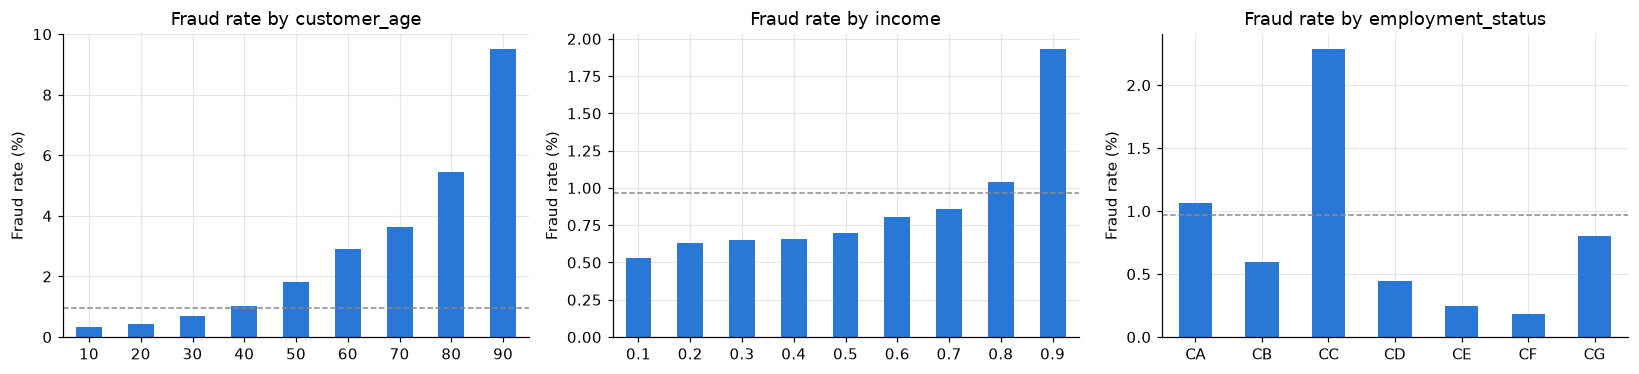

In [25]:
# Fraud rate by age, income and employment status (months 0-3)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ['customer_age', 'income', 'employment_status']):
    rate = train.groupby(col)[TARGET].mean() * 100
    rate.plot(kind='bar', ax=ax, color=BLUE, rot=0)
    ax.axhline(train[TARGET].mean() * 100, color=GREY, linestyle='--', linewidth=1)
    ax.set_title(f'Fraud rate by {col}')
    ax.set_ylabel('Fraud rate (%)')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

In [26]:
age_group = np.where(train['customer_age'] >= 50, '50+', 'under 50')

age_table = train.groupby(age_group)[TARGET].agg(['count', 'mean'])
age_table.columns = ['applications', 'fraud rate (%)']
age_table['fraud rate (%)'] = (age_table['fraud rate (%)'] * 100).round(2)
age_table['share of applications (%)'] = (age_table['applications'] / len(train) * 100).round(1)
display(age_table)

ratio = age_table.loc['50+', 'fraud rate (%)'] / age_table.loc['under 50', 'fraud rate (%)']
print(f'Applicants aged 50+ are {ratio:.1f}x as likely to be fraud as those under 50')

,applications,fraud rate (%),share of applications (%)
50+,104690,2.11,19.1
under 50,443285,0.69,80.9


Applicants aged 50+ are 3.1x as likely to be fraud as those under 50


**Proxy check**: we reuse the single-feature AUC, but this time to predict "aged 50+" instead of fraud. The closer a feature's AUC is to 1, the more it gives away a person's age.

In [27]:
is_50_plus = (train['customer_age'] >= 50).astype(int)
features_except_age = [col for col in all_features if col != 'customer_age']

proxy_table = single_feature_auc(train, is_50_plus, features_except_age, target_name='aged 50+')
proxy_table.head(10)

,feature,auc,relationship
0,date_of_birth_distinct_emails_4w,0.811,higher value → less likely aged 50+
1,housing_status,0.665,categories (see 3.4)
2,current_address_months_count,0.634,higher value → more likely aged 50+
3,phone_home_valid,0.616,higher value → more likely aged 50+
4,employment_status,0.605,categories (see 3.4)
5,device_os,0.590,categories (see 3.4)
6,credit_risk_score,0.585,higher value → more likely aged 50+
7,prev_address_months_count,0.575,higher value → less likely aged 50+
8,proposed_credit_limit,0.564,higher value → more likely aged 50+
9,phone_mobile_valid,0.558,higher value → less likely aged 50+


**Findings**
- Fraud rate rises steadily with age, from 0.33% at age 10 to 9.5% at age 90. It also rises with income (0.53% at the lowest decile, 1.93% at the highest).
- Applicants aged 50+ are 19% of applications but have a fraud rate of 2.11%, vs 0.69% for under 50 (**3.1x**). This gap is already in `base`, so it comes from the data itself, not from an added bias.
- **`date_of_birth_distinct_emails_4w` predicts "aged 50+" with AUC 0.81.** So simply leaving `customer_age` out of the model will not remove age information.

### **3.10 Other Variants**
All six files describe the same kind of applications, with slight variations:

| File | Built to have |
|---|---|
| `base` | No added bias (closest to the original data) |
| `variant_i` | Different group sizes |
| `variant_ii` | Different fraud rates between groups |
| `variant_iii` | Fraud is easier to detect for one group (adds columns `x1`, `x2`) |
| `variant_iv` | Like II, but only in the training months |
| `variant_v` | Like III, but only in the training months (adds `x1`, `x2`) |

The sections above already cover the shared columns, so here we only check **how the variants differ from base**.

In [28]:
variant_files = {
    'base': '../data/Base.csv',
    'variant_i': '../data/Variant I.csv',
    'variant_ii': '../data/Variant II.csv',
    'variant_iii': '../data/Variant III.csv',
    'variant_iv': '../data/Variant IV.csv',
    'variant_v': '../data/Variant V.csv',
}

group_rows = []      # fraud rate by age group, per variant and period
monthly_fraud = {}   # fraud rate per month, per variant
x_rows = []          # how well x1 / x2 detect fraud, where they exist

for name, path in variant_files.items():
    df = pd.read_csv(path)

    extra_cols = sorted(set(df.columns) - set(base.columns))
    print(f'{name}: {len(df):,} rows, extra columns: {extra_cols if extra_cols else "none"}')

    monthly_fraud[name] = df.groupby('month')[TARGET].mean() * 100

    periods = {'months 0-5': df[df['month'] <= 5], 'months 6-7': df[df['month'] >= 6]}
    for period, part in periods.items():
        is_50_plus = part['customer_age'] >= 50
        group_rows.append({
            'variant': name,
            'period': period,
            'share aged 50+ (%)': is_50_plus.mean() * 100,
            'fraud rate under 50 (%)': part.loc[~is_50_plus, TARGET].mean() * 100,
            'fraud rate 50+ (%)': part.loc[is_50_plus, TARGET].mean() * 100,
        })

        # x1 and x2: AUC for detecting fraud, separately within each age group
        for col in extra_cols:
            for group_name, in_group in [('under 50', ~is_50_plus), ('50+', is_50_plus)]:
                auc = roc_auc_score(part.loc[in_group, TARGET], part.loc[in_group, col])
                x_rows.append({'variant': name, 'period': period, 'column': col,
                               'age group': group_name, 'auc': round(max(auc, 1 - auc), 3)})

    del df  # free memory before loading the next file

group_table = pd.DataFrame(group_rows).round(2)
group_table['fraud rate ratio (50+ / under 50)'] = (
    group_table['fraud rate 50+ (%)'] / group_table['fraud rate under 50 (%)']).round(2)
group_table

base: 1,000,000 rows, extra columns: none


variant_i: 1,000,000 rows, extra columns: none


variant_ii: 1,000,000 rows, extra columns: none


variant_iii: 1,000,000 rows, extra columns: ['x1', 'x2']


variant_iv: 1,000,000 rows, extra columns: none


variant_v: 1,000,000 rows, extra columns: ['x1', 'x2']


,variant,period,share aged 50+ (%),fraud rate under 50 (%),fraud rate 50+ (%),fraud rate ratio (50+ / under 50)
0,base,months 0-5,18.77,0.75,2.21,2.95
1,base,months 6-7,16.48,1.10,2.93,2.66
2,variant_i,months 0-5,11.10,1.01,1.13,1.12
3,variant_i,months 6-7,10.95,1.38,1.56,1.13
4,variant_ii,months 0-5,50.60,0.34,1.70,5.00
5,variant_ii,months 6-7,50.53,0.46,2.32,5.04
6,variant_iii,months 0-5,50.60,1.09,1.12,1.03
7,variant_iii,months 6-7,50.53,1.08,1.11,1.03
8,variant_iv,months 0-5,50.60,0.36,1.83,5.08
9,variant_iv,months 6-7,50.53,1.08,1.11,1.03


,base,variant_i,variant_ii,variant_iii,variant_iv,variant_v
month,,,,,,
0,1.13,1.13,1.13,1.17,1.17,1.17
1,0.94,0.94,0.94,0.89,0.89,0.89
2,0.87,0.87,0.87,0.73,0.73,0.73
3,0.92,0.92,0.92,1.36,1.36,1.36
4,1.14,1.14,1.14,1.57,1.57,1.57
5,1.18,1.18,1.18,0.91,0.91,0.91
6,1.34,1.34,1.34,1.23,1.23,1.23
7,1.47,1.47,1.47,0.93,0.93,0.93


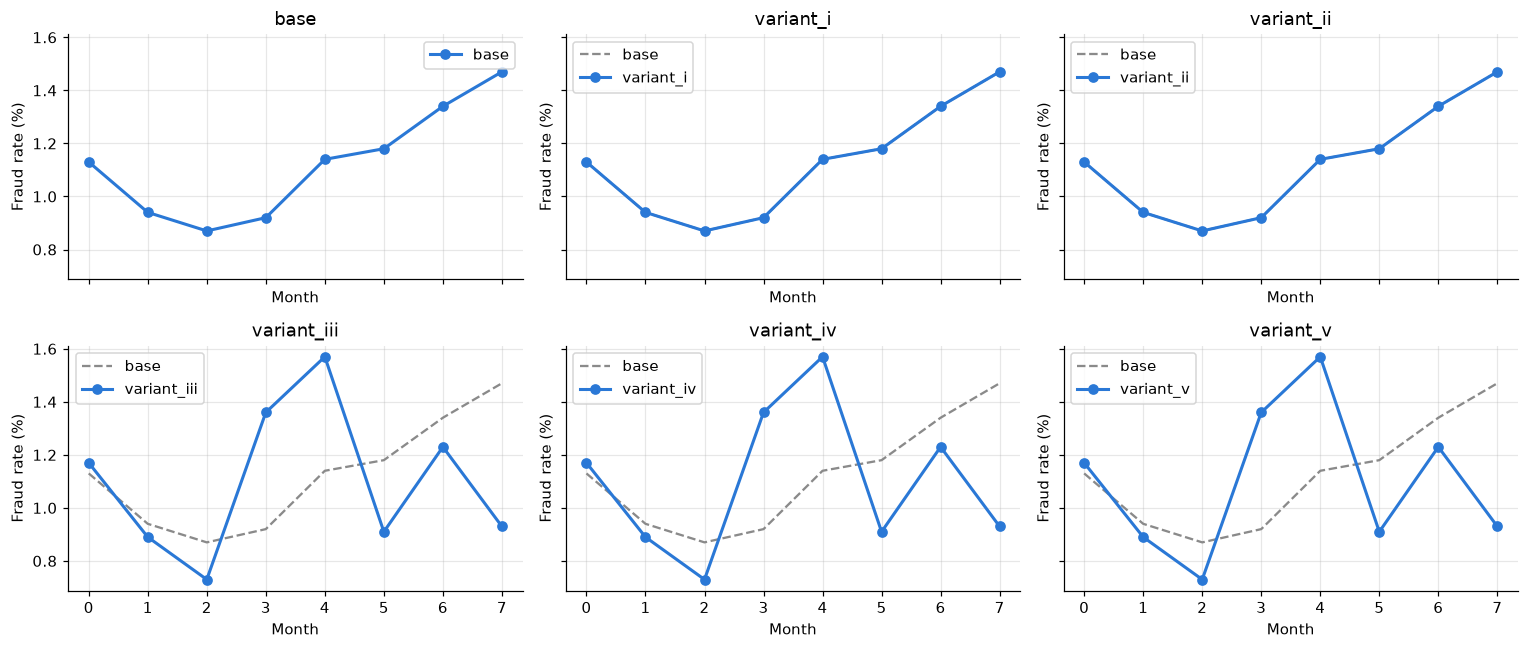

In [29]:
# Fraud rate per month in each variant
monthly_table = pd.DataFrame(monthly_fraud).round(2)
display(monthly_table)

# One small chart per variant, with base as a dashed grey line for comparison.
# (Several variants have exactly the same monthly rates, so on a single chart their lines hide each other.)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
for ax, name in zip(axes.flatten(), monthly_table.columns):
    if name != 'base':
        ax.plot(monthly_table.index, monthly_table['base'], color=GREY, linestyle='--', label='base')
    ax.plot(monthly_table.index, monthly_table[name], color=BLUE, marker='o', linewidth=2, label=name)
    ax.set_title(name)
    ax.set_xlabel('Month')
    ax.set_ylabel('Fraud rate (%)')
    ax.legend()
plt.tight_layout()
plt.show()

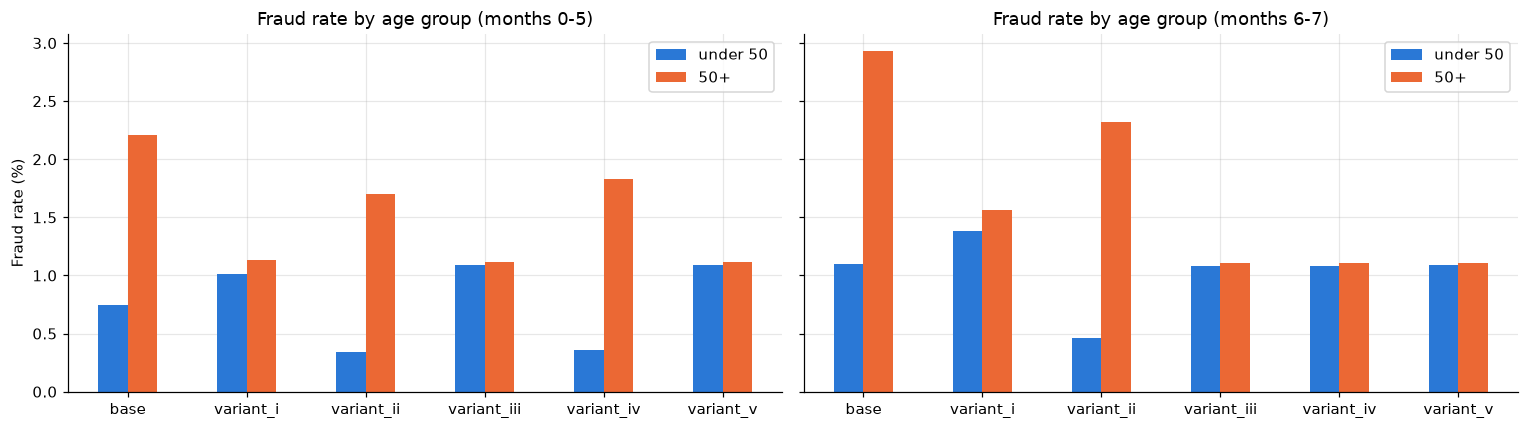

In [30]:
# Fraud rate by age group in each variant: early months vs late months
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, period in zip(axes, ['months 0-5', 'months 6-7']):
    part = group_table[group_table['period'] == period].set_index('variant')
    part[['fraud rate under 50 (%)', 'fraud rate 50+ (%)']].plot(
        kind='bar', ax=ax, color=[BLUE, ORANGE], rot=0)
    ax.set_title(f'Fraud rate by age group ({period})')
    ax.set_ylabel('Fraud rate (%)')
    ax.set_xlabel('')
    ax.legend(['under 50', '50+'])
plt.tight_layout()
plt.show()

In [31]:
# x1 and x2 (variants iii and v only): AUC for detecting fraud within each age group
x_table = pd.DataFrame(x_rows)
x_table.pivot_table(index=['variant', 'column', 'age group'], columns='period', values='auc')

period                        months 0-5  months 6-7
variant     column age group                        
variant_iii x1     50+             0.509       0.517
                   under 50        0.952       0.954
            x2     50+             0.513       0.501
                   under 50        0.951       0.950
variant_v   x1     50+             0.513       0.504
                   under 50        0.952       0.507
            x2     50+             0.515       0.504
                   under 50        0.951       0.510

**Findings**
- All six files have 1,000,000 rows and the same columns, except `variant_iii` and `variant_v`, which add `x1` and `x2`.
- The data matches what each variant was built to do:
  - `variant_i`: the 50+ group is much smaller (11% vs 19% in base), and the two groups have almost the same fraud rate (ratio 1.1).
  - `variant_ii`: the groups are the same size (51% / 49%), but the 50+ fraud rate is **5x** higher in every month.
  - `variant_iii`: same group sizes and fraud rates, but `x1` / `x2` detect fraud very well for under 50 (AUC 0.95) and not at all for 50+ (0.51).
  - `variant_iv`: the 5x gap exists in months 0-5 and **disappears** in months 6-7.
  - `variant_v`: `x1` / `x2` work for under 50 in months 0-5 (AUC 0.95), then become useless in months 6-7 (0.51).
- **The monthly fraud rates come in two identical sets:** `base`, `variant_i` and `variant_ii` match exactly, and so do `variant_iii`, `variant_iv` and `variant_v`. The variants move fraud *between age groups*, not between months. The second set also has a different time pattern: fraud peaks in months 3-4 (up to 1.57%) and is lower in the test months (1.23% and 0.93%), whereas base rises to 1.47%. So "the test months have more fraud" (3.2) is only true for base, I and II.
- **What this means:**
  - The same split (train on early months, test on months 6-7) works for every variant. For IV and V it is actually the point: the model learns from biased months and is tested on unbiased ones.
  - A model trained on `variant_v` will rely on `x1` / `x2` and then break on the test months. Preprocessing should have a switch for including `x1` / `x2`.

## **4. Summary: Findings → Actions**
Each finding, the action it led to, and where the action is carried out. Notebook 02 (NB02) builds the model from this table. Where an action was done differently from what was planned here, the last column says what was done.

| Finding | Action | Where it is done |
|---|---|---|
| Missing values are hidden as `-1` / negatives, and being missing is linked to fraud | Add a `<column>_missing` flag for each, then fill or leave the gap depending on the model | NB02 §3 (the flags; kept after testing in NB02 §4.4). The gaps are left as NaN for the tree models and filled with the median for logistic regression (NB02 §4.1) |
| `device_fraud_count` is always 0 | Drop it | NB02 §3 |
| `income` has floating-point noise | Round to 1 decimal place when loading | NB02 §3 |
| Long right tails (`days_since_request`, `prev_address_months_count`, ...) | Log transform for linear models only | NB02 §4.1 (logistic regression only) |
| Tiny categories (AE, CG, BF, BG) | Merge into "other" before one-hot encoding | NB02 §4.1, for logistic regression only: the one-hot encoder merges every category under 0.5% of rows into one "infrequent" column. The tree models keep the categories as they are |
| `velocity_*`, `zip_count_4w` shift strongly with month | Try dropping them vs making them relative to their month; choose on the validation month | NB02 §4.2-4.4: drop, ratio and month rank were tested. Month 4 could not separate them, so the drift check (NB02 §4.3) decided: the columns are replaced by ratios |
| 1.1% fraud, rising to 1.47% in the test months | Use recall at 5% FPR and PR-AUC, not accuracy. Calibrate on a held-out month | NB02 §2 (recall at 5% FPR is the main metric; PR-AUC is reported from NB02 §5). Calibration: notebook 04 §7, on month 5 |
| No single feature leaks; `month` tracks time | Never use `month` as a model feature | NB02 §2 (protocol) and §4.2 (`make_features` drops `month`) |
| Only 3 columns are Benford-eligible; fraud deviates more from Benford in 2 of them | Mention in the report as supporting evidence; not a model feature (it is a group-level test) | The report only; no notebook uses it |
| 50+ have 3.1x the fraud rate; `date_of_birth_distinct_emails_4w` is a strong age proxy | Keep `customer_age` alongside every prediction | NB02 §8 saves `customer_age` with every test prediction and reports predictive equality. The age gap is analysed in notebook 06 |
| Variants IV and V are only biased in months 0-5; `x1` / `x2` stop working in V's test months | Use the same split for all variants; make `x1` / `x2` a switch | NB02 §8 scores months 6-7 of every variant with the model trained on Base. Done differently for `x1` / `x2`: NB02 §3 drops them, because the Base model never sees them |